# Start


In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import pickle

# Load Data

In [2]:
train = pd.read_csv('C:/Users/Fong/Documents/VScode/ML/sgu26_machine_learning/Kaggle/HousePrices/sgu26_House-PricesAdvancedRegressionTechniques/input/train.csv')
test = pd.read_csv('C:/Users/Fong/Documents/VScode/ML/sgu26_machine_learning/Kaggle/HousePrices/sgu26_House-PricesAdvancedRegressionTechniques/input/test.csv')
print("Train Shape:", train.shape)
print("Test Shape:", test.shape)
print(train.info())

Train Shape: (1460, 81)
Test Shape: (1459, 80)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  Overa

# Kiểm tra ngoại lệ (Outliers)

Dùng quy tắc IQR để đánh dấu các giá trị cực đoan trong một số biến số quan trọng. Ngoại lệ không đồng nghĩa với dữ liệu sai; cần kiểm tra từng dòng trước khi quyết định giữ, biến đổi hoặc loại bỏ.

In [ ]:
# Đọc bản gốc riêng để kết quả không bị ảnh hưởng nếu các ô preprocessing đã chạy.
outlier_data = pd.read_csv("input/train.csv")
outlier_cols = ["SalePrice", "LotArea", "GrLivArea", "TotalBsmtSF", "GarageArea"]
outlier_flags = pd.DataFrame(index=outlier_data.index)
outlier_summary = []

for column in outlier_cols:
    q1 = outlier_data[column].quantile(0.25)
    q3 = outlier_data[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_flags[column] = (
        (outlier_data[column] < lower_bound)
        | (outlier_data[column] > upper_bound)
    )
    outlier_summary.append({
        "Biến": column,
        "Q1": q1,
        "Q3": q3,
        "Ngưỡng dưới": lower_bound,
        "Ngưỡng trên": upper_bound,
        "Số ngoại lệ": int(outlier_flags[column].sum()),
        "Tỷ lệ (%)": round(outlier_flags[column].mean() * 100, 2),
    })

print("Thống kê ngoại lệ theo quy tắc IQR:")
display(pd.DataFrame(outlier_summary).set_index("Biến").round(2))

# Liệt kê các mẫu bị đánh dấu, ưu tiên mẫu bất thường trên nhiều biến.
flagged_rows = outlier_flags.any(axis=1)
outlier_candidates = outlier_data.loc[
    flagged_rows, ["Id", *outlier_cols]
].copy()
outlier_candidates["Số biến ngoài IQR"] = outlier_flags.loc[flagged_rows].sum(axis=1)
outlier_candidates["Biến bị đánh dấu"] = outlier_flags.loc[flagged_rows].apply(
    lambda row: ", ".join(row.index[row].tolist()), axis=1
)
outlier_candidates = outlier_candidates.sort_values(
    ["Số biến ngoài IQR", "SalePrice"], ascending=[False, False]
)
print(f"Tổng số dòng có ít nhất một biến ngoài IQR: {flagged_rows.sum()}")
display(outlier_candidates.head(30))

# Một ví dụ kiểm tra theo ngữ cảnh: nhà rất rộng nhưng giá bán thấp.
suspicious_houses = outlier_data.loc[
    (outlier_data["GrLivArea"] > 4000) & (outlier_data["SalePrice"] < 300000),
    ["Id", "GrLivArea", "OverallQual", "SalePrice"],
]
print("Nhà có GrLivArea > 4000 nhưng SalePrice < 300000:")
display(suspicious_houses)

fig, axes = plt.subplots(1, len(outlier_cols), figsize=(16, 4))
for column, axis in zip(outlier_cols, axes):
    sns.boxplot(y=outlier_data[column], ax=axis)
    axis.set_title(column)
plt.tight_layout()
plt.show()

# Chec for NULL values 

# Train Data

In [3]:
print(train.isnull().sum())

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64


# Test Data

In [4]:
print(test.isnull().sum())

Id                 0
MSSubClass         0
MSZoning           4
LotFrontage      227
LotArea            0
                ... 
MiscVal            0
MoSold             0
YrSold             0
SaleType           1
SaleCondition      0
Length: 80, dtype: int64


# For Train Data

In [5]:
cat_col_train = ['FireplaceQu','GarageType','GarageFinish','MasVnrType','BsmtQual',
                  'BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2','FireplaceQu',
                  'GarageQual','GarageCond']

ncat_col_train = ['LotFrontage','GarageYrBlt','MasVnrArea']

for i in cat_col_train:
    train[i] = train[i].fillna(train[i].mode()[0])

for j in ncat_col_train:
    train[j] = train[j].fillna(train[j].mean())

# For Test Data

In [6]:
cat_col_test = ['FireplaceQu','GarageType','GarageFinish','MasVnrType','BsmtQual',
                 'BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2','FireplaceQu',
                 'GarageQual','GarageCond','MSZoning','Utilities','Exterior1st','Exterior2nd',
                 'KitchenQual','Functional','SaleType']

ncat_col_test = ['LotFrontage','GarageYrBlt','MasVnrArea','BsmtFinSF1','BsmtFinSF2',
                  'BsmtUnfSF','TotalBsmtSF','BsmtFullBath','BsmtHalfBath','GarageCars','GarageArea']

for i in cat_col_test:
    test[i] = test[i].fillna(test[i].mode()[0])

for j in ncat_col_test:
    test[j] = test[j].fillna(test[j].mean())


# Drop Colmns

Train Shape:  (1460, 76)
Test Shape:  (1459, 75)


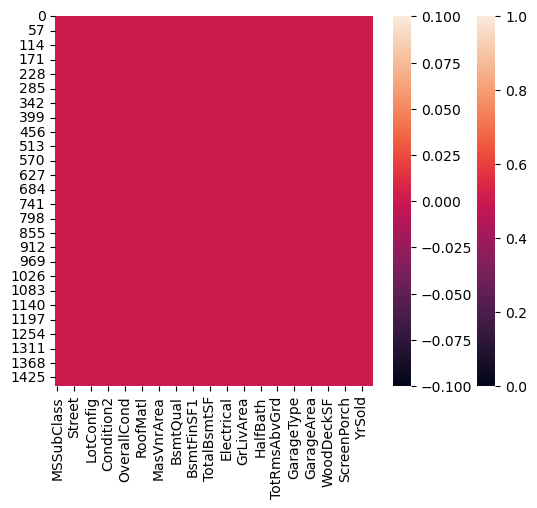

In [7]:
to_drop = ['Id','Alley','PoolQC','Fence','MiscFeature']

for k in to_drop:
    train.drop([k], axis = 1, inplace = True)
    test.drop([k], axis = 1, inplace = True)

sns.heatmap(train.isnull())
sns.heatmap(test.isnull())

print("Train Shape: ", train.shape)
print("Test Shape: ", test.shape)



In [8]:
final_df = pd.concat([train,test], axis = 0)
final_df.shape

(2919, 76)

# One-hot endcoding

In [9]:
final_df = pd.concat([train,test], axis = 0)
final_df.shape
# (2919, 76)

all_cat_col = ['MSZoning','Street','LotShape','LandContour','Utilities','LotConfig','LandSlope',
    'Neighborhood','Condition1','Condition2','BldgType','HouseStyle','RoofStyle','RoofMatl',
    'Exterior1st','Exterior2nd','MasVnrType','ExterQual','ExterCond','Foundation','BsmtQual',
    'BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2','Heating','HeatingQC','CentralAir',
    'Electrical','KitchenQual','Functional','FireplaceQu','GarageType','GarageFinish','GarageQual',
    'GarageCond','PavedDrive','SaleType','SaleCondition']

def cat_onehot_encoding(multicol):
    df_final = final_df
    i = 0
    for fields in multicol:
        print(fields)
        df1 = pd.get_dummies(final_df[fields], drop_first = True)

        final_df.drop([fields], axis = 1, inplace = True)
        if i == 0:
            df_final = df1.copy()
        else:
            df_final = pd.concat([df_final, df1], axis = 1)
        i = i + 1

    df_final = pd.concat([final_df, df_final], axis = 1)

    return df_final

final_df = cat_onehot_encoding(all_cat_col)

final_df.shape

MSZoning
Street
LotShape
LandContour
Utilities
LotConfig
LandSlope
Neighborhood
Condition1
Condition2
BldgType
HouseStyle
RoofStyle
RoofMatl
Exterior1st
Exterior2nd
MasVnrType
ExterQual
ExterCond
Foundation
BsmtQual
BsmtCond
BsmtExposure
BsmtFinType1
BsmtFinType2
Heating
HeatingQC
CentralAir
Electrical
KitchenQual
Functional
FireplaceQu
GarageType
GarageFinish
GarageQual
GarageCond
PavedDrive
SaleType
SaleCondition


(2919, 236)

# Remove duplicate columns

In [10]:
final_df = final_df.loc[:, ~final_df.columns.duplicated()]
final_df.shape

(2919, 176)

# Divide data for train and test

In [11]:
df_train = final_df.iloc[:1460,:]
df_test = final_df.iloc[1460:,:]

In [12]:
df_test.drop(['SalePrice'], axis = 1, inplace = True)

C:\Users\Fong\AppData\Local\Temp\ipykernel_24100\1609311842.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test.drop(['SalePrice'], axis = 1, inplace = True)


In [13]:
print("Train Shape: ", df_train.shape)
print("Test Shape: ", df_test.shape)

Train Shape:  (1460, 176)
Test Shape:  (1459, 175)


# Traning Data

In [14]:
x_train = df_train.drop(['SalePrice'], axis = 1)
y_train = df_train['SalePrice']

# XGBoost

In [15]:
import xgboost

xgb_model = xgboost.XGBRegressor()
xgb_model.fit(x_train, y_train)

param = {
    'n_estimators': [1500, 2000, 2500, 3000],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.02, 0.03, 0.05],
    'subsample': [0.7, 0.8],
    'colsample_bytree': [0.5, 0.7, 0.8],
    'reg_alpha': [0.01, 0.05, 0.1],
    'reg_lambda': [1, 3, 5],
    'min_child_weight': [1, 3, 5],
    'booster': ['gbtree']
}

from sklearn.model_selection import RandomizedSearchCV

random_cv = RandomizedSearchCV(estimator=xgb_model,
                                param_distributions=param,
                                cv=5, n_iter=50,
                                scoring='neg_mean_absolute_error', n_jobs=4,
                                verbose=5,
                                return_train_score=True,
                                random_state=42)
random_cv.fit(x_train, y_train)

random_cv.best_estimator_

xgb_model = xgboost.XGBRegressor(
    booster='gbtree',
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=3,
    n_estimators=2000,
    objective='reg:squarederror',
    reg_alpha=0.05,
    reg_lambda=3,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    device='cpu',
    random_state=0
)

xgb_model.fit(x_train, y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


,objective,'reg:squarederror'
,base_score,None
,booster,'gbtree'
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,'cpu'
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


# Save Model

In [16]:
f = "xgb_model.pkl"
pickle.dump(xgb_model, open(f,'wb'))


# Decision Tree

In [17]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(x_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


# Predictions

In [18]:
pred_dt = dt_model.predict(df_test)
print(pred_dt.shape)

(1459,)


# Submissions

In [19]:
sub_df = pd.read_csv('input/sample_submission.csv')
sub_df['SalePrice'] = pred_dt
sub_df.to_csv('sample_sub_dt.csv', index=False)

# Artificial Neural Network

In [20]:
import keras
from keras import ops
from keras.models import Sequential
from keras.layers import Dense

def root_mean_squared_error(y_true, y_pred):
    return ops.sqrt(ops.mean(ops.square(y_pred - y_true)))

# Model

In [21]:
from keras import Input

x_train_nn = x_train.apply(pd.to_numeric, errors='coerce').fillna(0).astype('float32')
y_train_nn = pd.to_numeric(y_train, errors='coerce').astype('float32')

nn_model = Sequential([
    Input(shape=(x_train_nn.shape[1],)),
    Dense(50, kernel_initializer='he_uniform', activation='relu'),
    Dense(25, kernel_initializer='he_uniform', activation='relu'),
    Dense(50, kernel_initializer='he_uniform', activation='relu'),
    Dense(1, kernel_initializer='he_uniform')
])

nn_model.compile(loss=root_mean_squared_error, optimizer='Adamax')
nn_model.fit(x_train_nn, y_train_nn, validation_split=0.25, batch_size=10, epochs=1000)
nn_model.save('nn_model.keras')

Epoch 1/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 179004.3125 - val_loss: 146056.6406
Epoch 2/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 100315.0703 - val_loss: 64083.4023
Epoch 3/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 71031.8516 - val_loss: 62191.7969
Epoch 4/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 68858.0078 - val_loss: 60759.6719
Epoch 5/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 66215.9453 - val_loss: 59420.0273
Epoch 6/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 63973.2148 - val_loss: 58009.3320
Epoch 7/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 61732.2734 - val_loss: 56918.9023
Epoch 8/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 59977.8242 - val_loss: 55609.8672
Epoch 9/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 57918.6211 - val_loss: 54437.7656
Epoch 10/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 56513.1172 - val_loss: 53274.6367
Epoch 11/1000
110/110 ━━━━━━━━━━━━━━

# Predictions

In [22]:
x_test_nn = df_test.apply(pd.to_numeric, errors='coerce').fillna(0).astype('float32')
pred_nn = nn_model.predict(x_test_nn, verbose=0).ravel()
print(pred_nn.shape)

(1459,)


# Submission

In [23]:
sub_df = pd.read_csv('input/sample_submission.csv')
sub_df['SalePrice'] = pred_nn
sub_df.to_csv('sample_sub_nn.csv', index=False)